# PricePulse BD — Stage 2: what the prices say

Dhaka retail prices for 61 essential commodities, May 2020 → today, scraped from the
Trading Corporation of Bangladesh (TCB) daily sheets and cleaned in Stage 1
(see the README for the data audit). This notebook asks five questions:

1. **How much have prices risen, and for what?** — basket index, per-item change
2. **Can the scraped data be trusted?** — comparison with an independent WFP survey
3. **When do prices spike?** — robust anomaly detection, checked against known shocks
4. **Do festivals move prices?** — Ramadan / Eid event study with a placebo test
5. **Which prices move together?** — correlation structure and import→local lead-lag

Heavy results (the festival permutation tests) are precomputed by `python -m analysis.run`
and read from `outputs/`; everything else is computed live below.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np
from IPython.display import display
from analysis import data, eda, spikes, validate_wfp, comovement, figures
pd.set_option("display.precision", 1)
%matplotlib inline

daily = data.daily_long()
print(f"{len(daily):,} daily observations · {daily.commodity_id.nunique()} commodities · "
      f"{daily.date.min():%d %b %Y} → {daily.date.max():%d %b %Y}")
daily.source.value_counts(normalize=True).mul(100).round(1).rename("% of rows by source")

105,094 daily observations · 61 commodities · 17 May 2020 → 12 Nov 2026


source
report            70.9
backfill_year     17.6
backfill_week      6.2
backfill_month     5.3
Name: % of rows by source, dtype: float64

## 1. How much have prices risen — and for what?

A Jevons index (geometric mean of price relatives — the standard elementary CPI
formula, indifferent to whether an item is quoted per kg, litre or hali) over the
20-item core basket, base = Bangladesh fiscal year 2020-21.

Core basket index, latest complete month: 140.6 (FY2020-21 = 100)


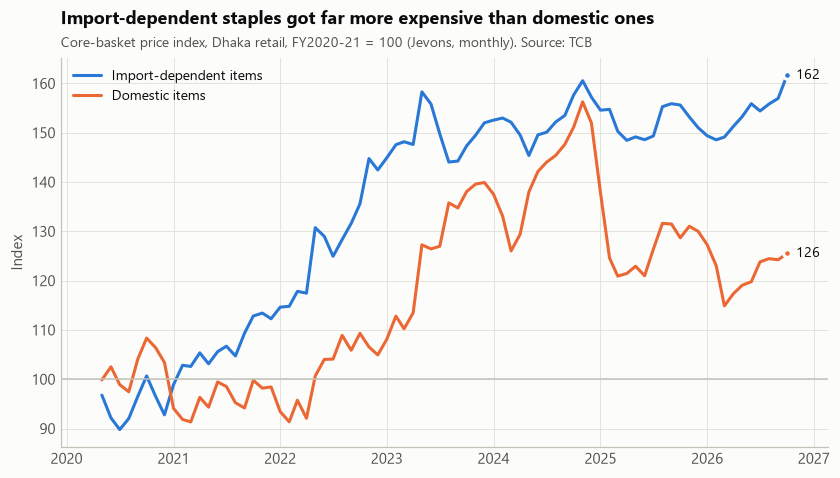

In [2]:
idx = eda.basket_index()
by_supply = eda.basket_by_supply()
inf = eda.item_inflation()
test = eda.import_vs_domestic(inf)
print(f"Core basket index, latest complete month: {idx.iloc[-2]:.1f} (FY2020-21 = 100)")
figures.basket(idx, by_supply);

The two halves of the basket tell different stories. Import-dependent items (wheat
flour, edible oil, sugar, lentils, dates…) climbed steadily through 2022-23 — the
period of the taka's sharp depreciation and the global commodity shock — and **never
came back down**. Domestic items rose later and are much more volatile: they peaked
in late 2024 and fell back as harvests came in.

Is the gap real or an artefact of which items happened to be in each group? Unit =
commodity (pack-size duplicates collapsed), permutation test on mean log change:

In [3]:
pd.Series(test).to_frame("value")

,value
n_import,1.9e+01
n_domestic,2.1e+01
median_change_import_pct,7.1e+01
median_change_domestic_pct,3.9e+01
mean_log_diff,1.6e-01
p_permutation_one_sided,2.2e-03
p_mannwhitney_one_sided,4.0e-03


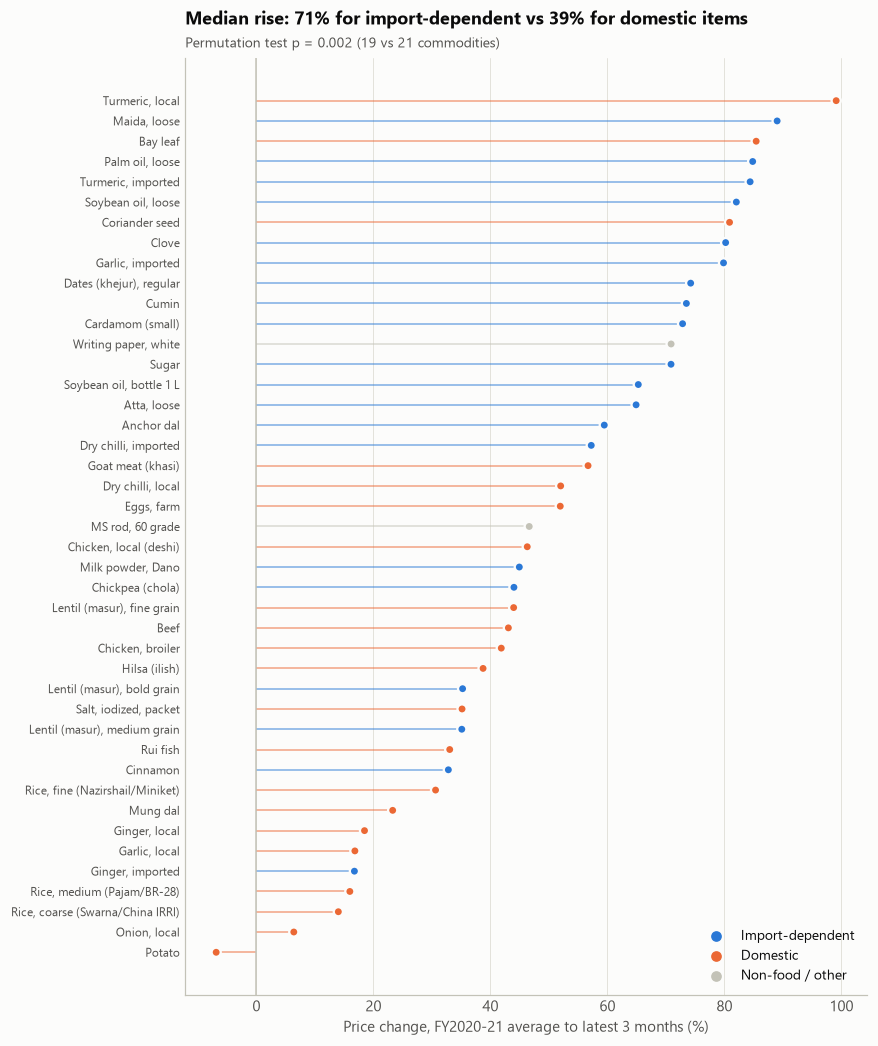

In [4]:
figures.inflation_dots(inf, test);

**Finding 1.** Import-dependent essentials rose a median **~71%** since FY2020-21 versus
**~39%** for domestically produced ones (permutation p ≈ 0.002). Rice — the single
most important item for household budgets — rose only 14-31% depending on grade.

*Caveat:* the import/domestic grouping is a judgement call documented in
`analysis/data.py`; a few items (lentils, turmeric) are mixed-origin. The result is
robust to the rank-based Mann-Whitney test as well.

## 2. Can the scraped data be trusted?

The World Food Programme runs its own monthly price survey. If the scraper, parser or
backfill were wrong, TCB would drift away from it.

,months,level_corr,change_corr,median_ratio_tcb_to_wfp
commodity_id,,,,
atta_loose,68,0.9,3.2e-01,0.8
rice_coarse,35,0.8,-4.0e-02,1.0
palm_loose,43,1.0,6.3e-01,1.0
lentil_bold,33,0.9,6.3e-01,1.0
soybean_loose,21,1.0,7.6e-01,1.0
sugar,21,1.0,4.4e-01,1.0
garlic_imported,21,0.9,8.3e-01,1.0
green_chili,14,0.8,4.1e-01,0.9
eggs,21,0.9,8.1e-01,1.0


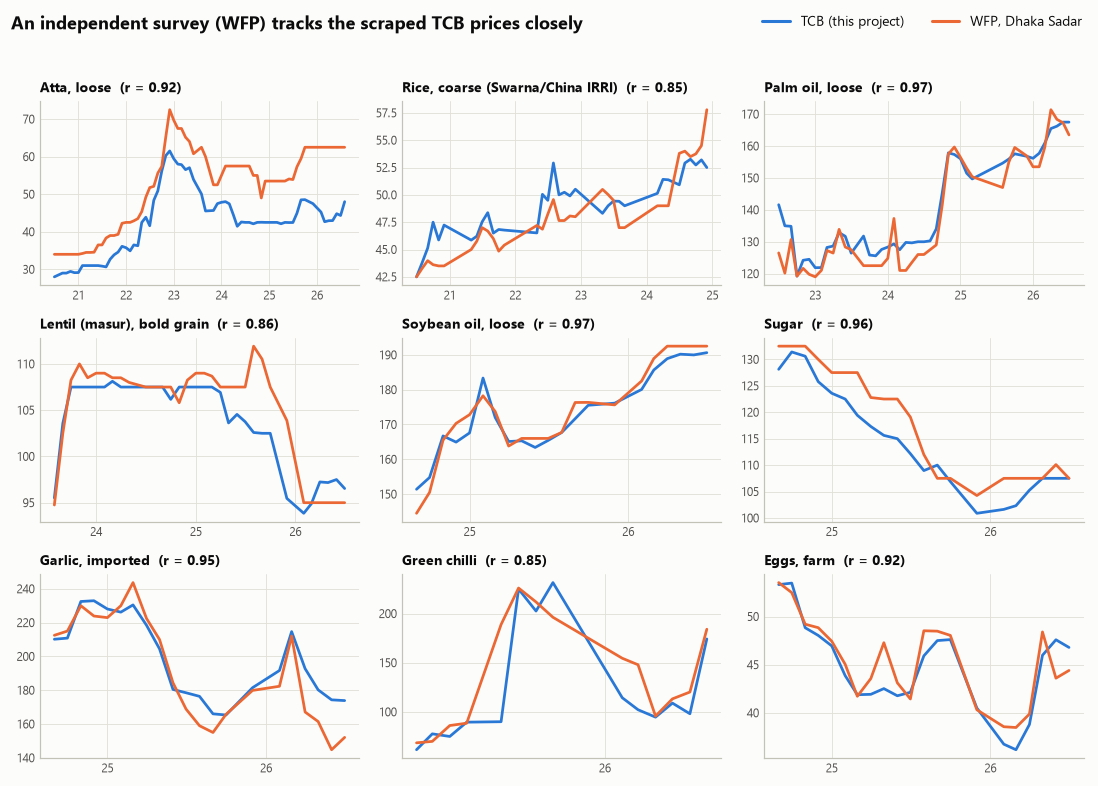

In [5]:
wsum, wser = validate_wfp.compare()
display(wsum[["months", "level_corr", "change_corr", "median_ratio_tcb_to_wfp"]].round(2))
figures.wfp_validation(wsum, wser);

**Finding 2.** Price *levels* agree closely (r = 0.85–0.97; median TCB/WFP ratio
0.97–1.03 for eight of nine items). Two honest exceptions: WFP's "wheat flour" sits
~16% above TCB's loose atta from 2023 (likely a different product mix), and
month-to-month *changes* in coarse rice don't correlate — rice barely moves, so its
monthly changes are mostly noise in both surveys.

## 3. When do prices spike?

For each item and day: the 14-day log change, scored against the item's **own**
trailing year with a robust z-score (median / MAD, so past shocks don't inflate the
baseline). A spike needs z ≥ 3.5 **and** a rise of at least 10%; flagged days within
10 days merge into one episode.

**Validation.** Externally documented supply shocks with exact dates
(`data/reference/known_shocks.csv`) — was each one detected?

In [6]:
up = spikes.detect("up")
known = spikes.evaluate_known()
print(f"{len(up)} upward spike episodes across {up.commodity_id.nunique()} commodities")
known

224 upward spike episodes across 50 commodities


,date,commodity_id,event,evaluable,detected,lag_days,change_14d_pct
0,2020-09-14,onion_local,India bans onion exports,False,None,NaN,NaN
1,2020-09-14,onion_imported,India bans onion exports,False,None,NaN,NaN
2,2022-04-28,palm_loose,Indonesia palm oil export ban takes effect,True,True,-2.0,19.6
3,2022-04-28,soybean_loose,Indonesia palm oil export ban takes effect,True,True,-1.0,22.5
4,2022-05-13,atta_loose,India bans wheat exports,True,True,0.0,31.5
5,2022-05-13,maida_loose,India bans wheat exports,True,True,5.0,12.4
6,2023-12-08,onion_local,India bans onion exports,True,True,1.0,68.2
7,2023-12-08,onion_imported,India bans onion exports,True,True,1.0,73.7


All six evaluable shocks are detected within 0–5 days; the palm/soybean oil episodes
start 1–2 days *before* Indonesia's ban took effect — the market reacted to the
announcement. The September 2020 onion ban falls inside the detector's warm-up period
(it needs ~7 months of history) and is reported as not evaluable rather than counted.

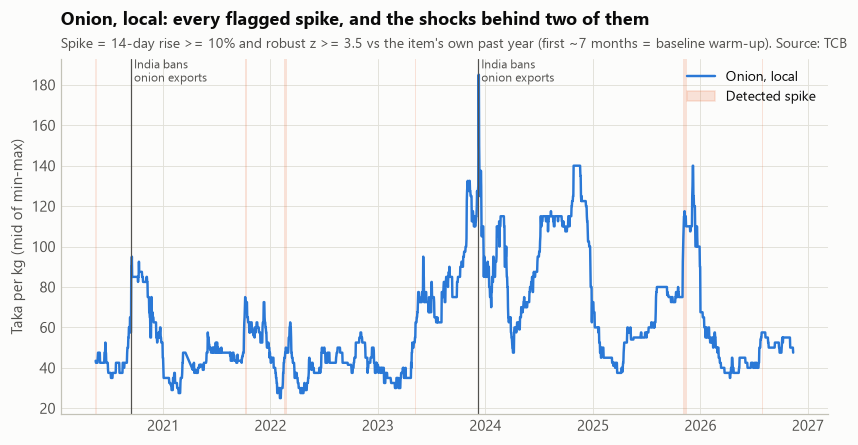

In [7]:
figures.spike_series("onion_local", up, pd.read_csv(data.REF / "known_shocks.csv"));

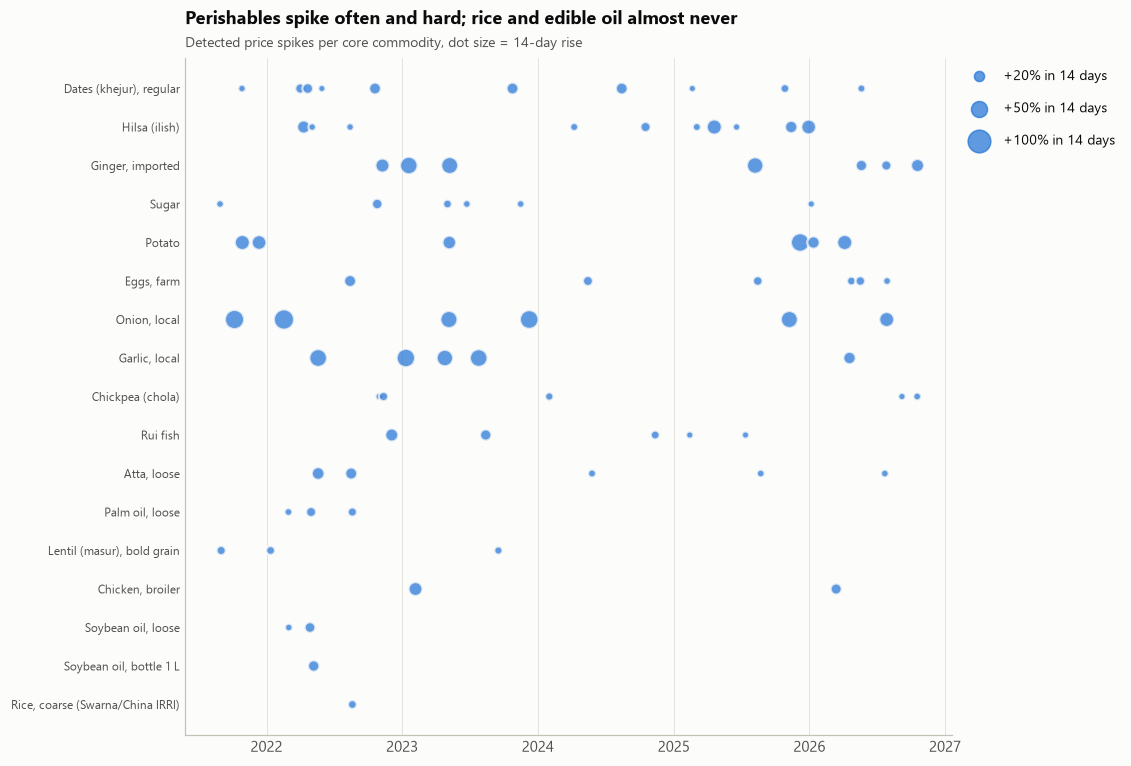

In [8]:
figures.spike_timeline(up, data.core_ids());

In [9]:
(up[up.commodity_id.isin(data.core_ids())]
   .nlargest(10, "change_14d_pct")
   [["name_en", "start", "end", "change_14d_pct", "price_before", "price_peak"]])

,name_en,start,end,change_14d_pct,price_before,price_peak
23,"Onion, local",2022-02-16,2022-02-25,80.0,25.0,62.5
9,"Onion, local",2021-10-05,2021-10-13,72.4,43.5,75.0
131,"Onion, local",2023-12-09,2023-12-09,68.2,110.0,185.0
89,"Garlic, local",2023-01-11,2023-01-14,66.7,75.0,130.0
194,Potato,2025-12-07,2025-12-10,66.7,22.5,37.5
46,"Garlic, local",2022-05-17,2022-05-24,61.5,65.0,105.0
118,"Garlic, local",2023-07-25,2023-07-30,60.7,145.0,225.0
88,"Ginger, imported",2023-01-11,2023-01-24,60.0,120.0,200.0
107,"Onion, local",2023-05-07,2023-05-09,57.1,35.0,77.5
191,"Onion, local",2025-11-04,2025-11-15,56.7,75.0,117.5


**Finding 3.** Perishables (onion, garlic, potato, ginger) produce the biggest and most
frequent spikes; rice and bottled oil almost never spike — their prices move in
administered steps or slow drifts.

*Limitations:* (a) the detector is built for *sudden* moves — the autumn-2024 egg price
climb (+15% over 8 weeks, never +10% in 14 days) is not flagged, by design; (b) items
quoted as wide quality ranges (dates: ৳200–450) show step "spikes" when TCB re-bands
the range, which is a reporting change rather than a market move.

## 4. Do festivals move prices?

For each festival occurrence, the **run-up** = mean log price in the 14 days before
minus the mean 31–60 days before. Prices drift up anyway, so the festival run-up is
compared with the same statistic at every non-festival Thursday (**placebo**), and
tested by permutation (10,000 draws of *k* placebo dates, *k* = festival years).
With ~60 items tested per festival, q-values control the false discovery rate
(Benjamini–Hochberg).

In [10]:
fest = pd.read_csv(data.OUTPUTS / "festival_effects.csv")
sig = fest[fest.q_value < 0.10].sort_values(["festival", "abnormal_pct"])
sig[["festival", "name_en", "n_years", "runup_pct", "placebo_pct", "abnormal_pct",
     "years_above_placebo", "q_value"]].round(3)

,festival,name_en,n_years,runup_pct,placebo_pct,abnormal_pct,years_above_placebo,q_value
3,Eid-ul-Adha,"Garlic, imported",7,-8.0,3.4e+00,-11.1,3,1.6e-02
2,Eid-ul-Adha,"Chicken, broiler",7,-8.3,1.6e+00,-9.7,0,1.0e-02
1,Eid-ul-Adha,"Soybean oil, loose",7,-3.1,2.4e+00,-5.3,0,5.0e-03
6,Eid-ul-Adha,"Palm oil, loose",7,-2.6,2.4e+00,-4.9,0,9.4e-02
5,Eid-ul-Adha,"Milk powder, Diploma",7,2.2,6.7e-01,1.6,4,9.4e-02
0,Eid-ul-Adha,"Chicken, local (deshi)",7,4.6,-2.8e+00,7.6,6,5.0e-03
4,Eid-ul-Adha,"Eggs, farm",7,7.6,-2.3e+00,10.2,5,2.7e-02
56,Eid-ul-Fitr,"Onion, local",5,-26.1,2.0e+00,-27.5,1,1.3e-02
52,Eid-ul-Fitr,"Garlic, local",5,-17.7,5.6e-01,-18.2,1,5.0e-03
54,Eid-ul-Fitr,Chickpea (chola),5,-3.9,3.5e+00,-7.2,0,7.0e-03


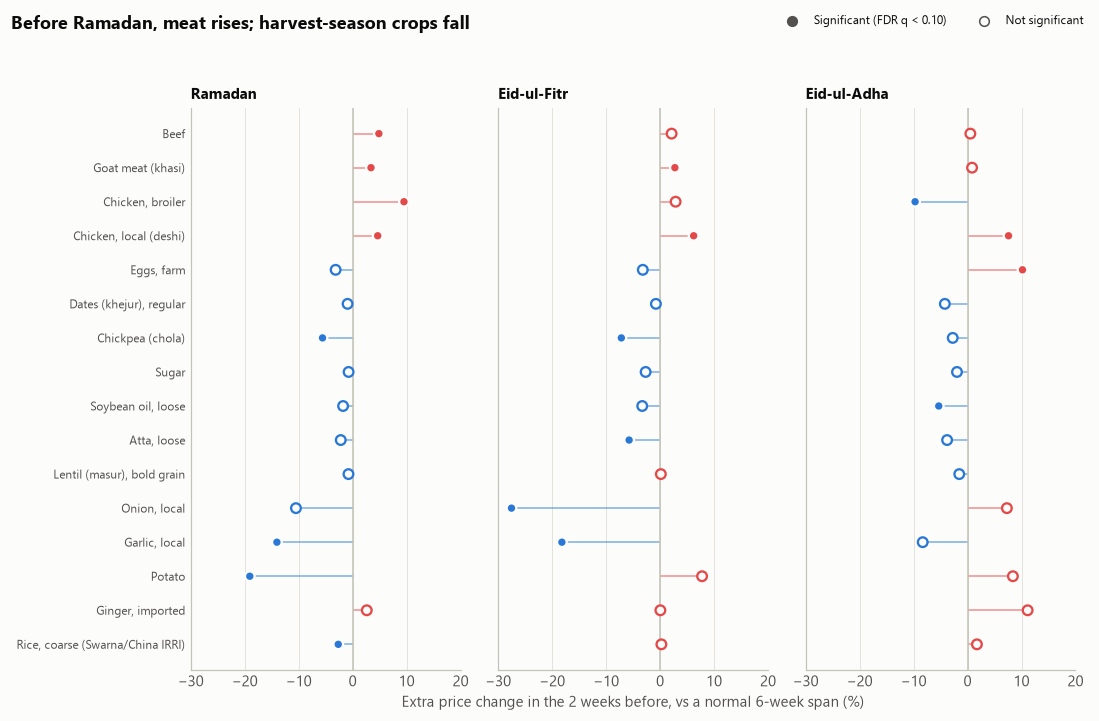

In [11]:
from analysis.run import EFFECT_ITEMS, RAMADAN_ITEMS
figures.festival_effects(fest, EFFECT_ITEMS);

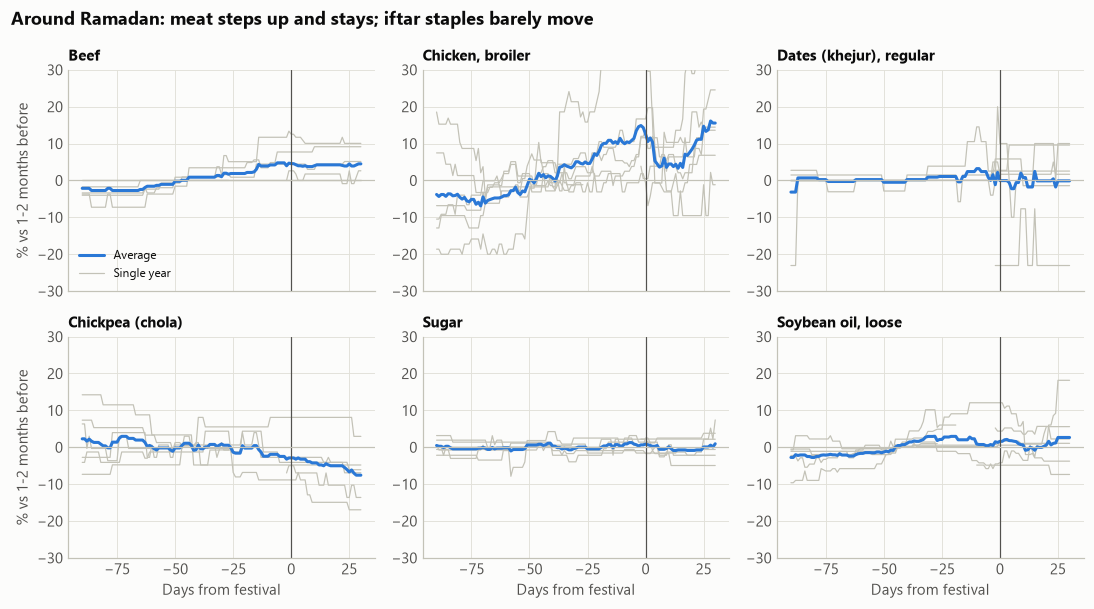

In [12]:
figures.festival_paths("ramadan_start", RAMADAN_ITEMS,
                       "Around Ramadan: meat steps up and stays; iftar staples barely move");

**Finding 4.**

* **Meat, not iftar staples, carries the Ramadan premium.** Beef (+4.9%), goat (+3.4%)
  and chicken (broiler +9.5%, deshi +4.6%) rise beyond the placebo before Ramadan —
  and beef's step *does not reverse* afterwards. Sugar is flat, dates move ~2% and
  chickpea actually gets *cheaper* into and through Ramadan. One plausible explanation
  (not tested here) is that iftar staples are where government action concentrates —
  TCB's subsidised truck sales and pre-Ramadan import duty cuts.
* **Eid-ul-Adha flips chicken.** Broiler falls ~10% in the fortnight before the
  sacrificial Eid (demand shifts to cattle and goats) while deshi chicken and eggs rise.
* **Harvest season masquerades as a festival effect.** Local onion, garlic and potato
  fall sharply before Ramadan/Eid-ul-Fitr — because in 2022-26 those festivals fell in
  Feb–April, exactly the harvest. That is seasonality, not the festival; only a longer
  history (Ramadan cycles through the calendar in ~33 years) can separate the two.

*Also note:* Ramadan and Eid-ul-Fitr are ~30 days apart, so their windows overlap and
the two tests are not independent. Five to seven festival years per test is a small
sample; effects are reported with consistency counts (`years_above_placebo`) for that
reason.

## 5. Which prices move together?

Correlation of weekly log price changes, ordered by hierarchical clustering.

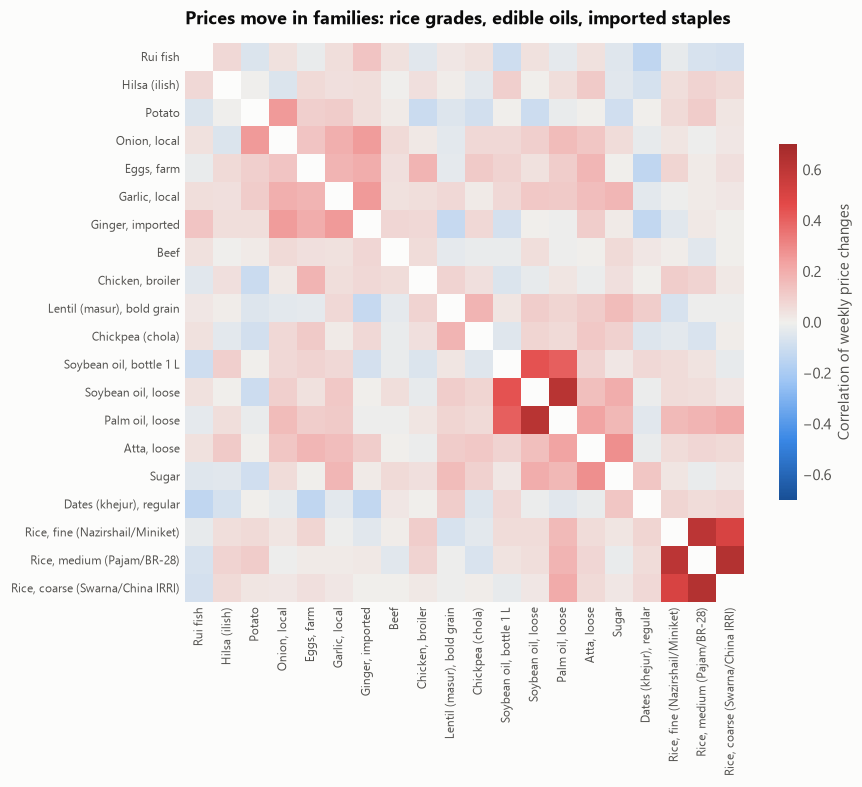

In [13]:
corr = comovement.correlation()
figures.correlation_heatmap(corr);

In [14]:
comovement.lead_lag().round(3)

,leader,follower,weeks,corr_same_week,corr_leader_1w_earlier,best_lag_weeks,best_corr,granger_p_leader_to_follower,granger_p_follower_to_leader
0,onion_imported,onion_local,253,0.7,2.6e-01,0,0.7,9.2e-01,1.8e-02
1,garlic_imported,garlic_local,329,0.4,1.4e-01,0,0.4,3.5e-01,1.4e-01
2,ginger_imported,ginger_local,308,0.3,7.0e-02,0,0.3,7.8e-01,1.3e-01
3,chili_dry_imported,chili_dry_local,329,0.4,-2.8e-02,0,0.4,7.2e-02,5.0e-03
4,palm_loose,soybean_loose,327,0.6,2.8e-01,0,0.6,3.6e-01,6.0e-03


**Finding 5.** Prices move in families — the three rice grades (r ≈ 0.5–0.65), edible
oils (0.4–0.6), and a looser "imported staples" group (atta, sugar, palm oil). Beyond
those, week-to-week moves are largely item-specific, which is why per-item spike
detection beats a single basket alarm.

Does the imported variety **lead** the local one? No evidence: imported and local
onion move in the *same* week (r ≈ 0.70), and Granger tests find no predictive power
from imported to local. If anything a few tests point the other way (local → imported,
p ≈ 0.005–0.02), but with ten tests run that is suggestive only.

## Summary

| # | Question | Answer |
|---|---|---|
| 1 | What got expensive? | Import-dependent essentials: median +71% vs +39% domestic since FY2020-21 (p ≈ 0.002) |
| 2 | Is the data right? | Tracks WFP's independent survey, r = 0.85–0.97 |
| 3 | Spikes? | Detector catches 6/6 documented shocks within 0–5 days; perishables dominate |
| 4 | Festivals? | Ramadan premium is in meat, not iftar staples; Eid-ul-Adha cuts broiler prices |
| 5 | Co-movement? | Families (rice, oils, imported staples); imports don't lead local prices |

**Next (Stage 3):** short-horizon forecasts with honest uncertainty — seasonal-naive,
ETS and gradient-boosting models compared on rolling-origin backtests.